# Iris – Exploratory Data Analysis (EDA)

Analiza zbioru Iris w ramach projektu Machine Learning.

## 1. Wczytywanie danych

Zbiór zawiera 150 obserwacji i trzy gatunki irysów.

In [1]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

iris = load_iris(as_frame=True)
df = iris.data.copy()
df['species'] = iris.target.map(
    dict(enumerate(iris.target_names))
)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. Statystyki opisowe

In [2]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 3. Kontrola jakości danych

In [3]:
print('Brakujące wartości:')
print(df.isnull().sum())

print('\nDuplikaty:', df.duplicated().sum())

Brakujące wartości:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplikaty: 1


## 4. Porównanie gatunków

In [4]:
df.groupby('species').mean().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


## 5. Wizualizacja cech

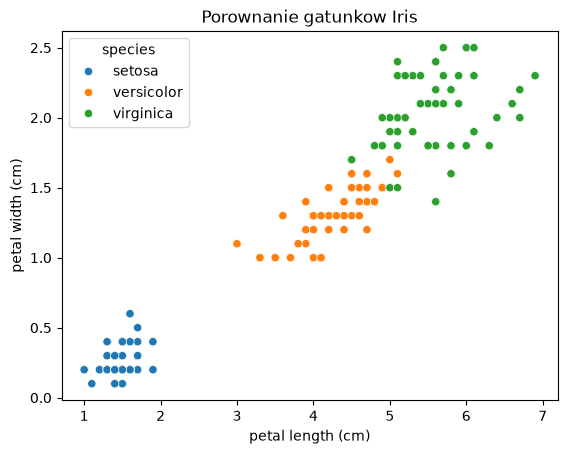

In [5]:
sns.scatterplot(
    data=df,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='species'
)
plt.title('Porownanie gatunkow Iris')
plt.show()

## 6. Macierz korelacji

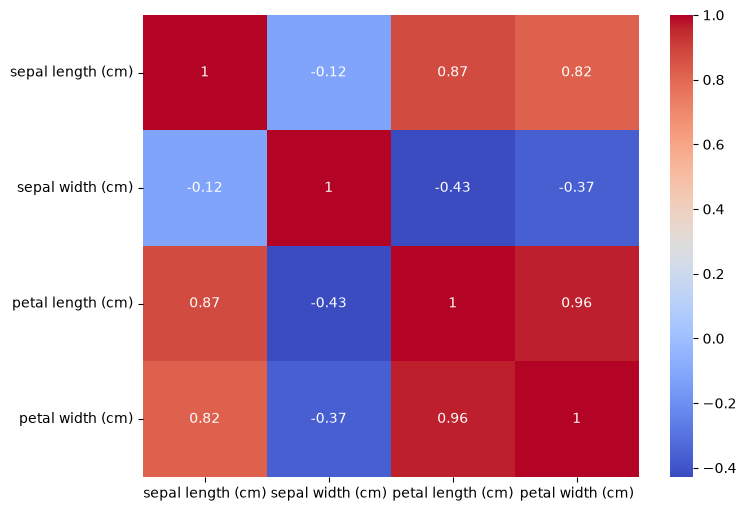

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm'
)
plt.show()

## 7. Wnioski

- Zbiór nie zawiera brakujących wartości.
- Występuje jeden zduplikowany wiersz.
- Długość i szerokość płatków są silnie skorelowane.
- Cechy płatków pomagają odróżniać gatunki.